# Lab3 ML - Rohit Solanki

---
# 1 Part 1 – Class imbalance and evaluation
### Assume that a dataset contains 900 legitimate transactions and 100 fraudulent transactions.

### Q1. Explain why a classifier trained on an imbalanced dataset might favor the majority class.

#### A classifier just wants to minimize overall errors, so it takes the easy way out and learns to always guess the majority class. In simple formula we call it influence even in real life.

### Q2. Why can accuracy be insufficient for evaluating fraud detection?

#### With a 900/100 split, a model can blindly guess "legitimate" every single time and score 90% accuracy, while totally failing to detect any actual fraud.

### Q3. Explain the difference between undersampling and oversampling.
#### Undersampling just deletes data from big class and Oversampling makes small class big by repeating some data points. Both are used for balancing dataset. Basically we can consider undersampling is make the data small, while oversampling means make data big 

---
# 2 Part 2 – Understanding the algorithms

### Q4. Why can Tomek Links be useful for observations located near a class boundary?
#### It clean up the borders between the two classes by deleting majority points that overlap with minority classes points.

### Q5. What is the main difference between the selection strategies used by Tomek Links and NearMiss v1?
#### it's just look for specific overlapping pairs to remove, but NearMiss v1 actively deletes majority points closest to the minority class

### Q6. Why can NearMiss remove many more majority-class observations than Tomek Links ?
#### Near Miss can throw away a massive amount of your data because it keeps tossing points until everything is balanced out, taking a lot of heavy cutting. Tomek Links is way more relaxed and only removes a tiny handful of those specific border points, leaving most of the original data completely untouched

### Q7. Does either technique guarantee better classification performance? Explain.
#### No, neither technique guarantee a better model. When you throw away real data, you might lose really helpful clues. sometimes forcing the sides to be perfectly equal actually confuses the model. So doing this could actually make final score worse.

---
# 3 Part 3 – Generate the dataset

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from collections import Counter

X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.90, 0.10], # 90% normal, 10% fraud
    class_sep=0.8,
    random_state=42
)

print("Original distribution:", Counter(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print("Training distribution:", Counter(y_train))
print("Test distribution:", Counter(y_test))

Original distribution: Counter({np.int64(0): 895, np.int64(1): 105})
Training distribution: Counter({np.int64(0): 626, np.int64(1): 74})
Test distribution: Counter({np.int64(0): 269, np.int64(1): 31})


### Q8. How many observations belong to each class in the training set?
#### total it have 700 points in training. so there might be 630 legitimate and other samples are bad.

### Q9. Why is stratify=y used when splitting the data?
#### it's used to to add 90-10 ratio to train and test split. Because in both train and test we want to have both the types of data.

---
# 4 Part 4 – Visualize the original training set

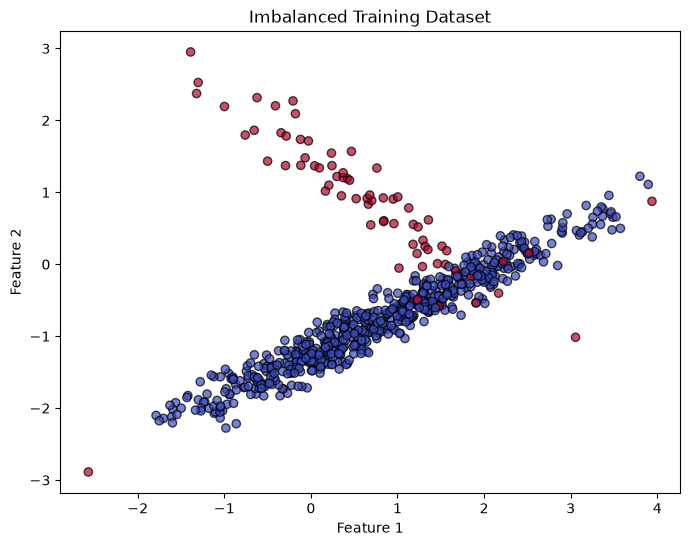

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train, cmap="coolwarm",
    alpha=0.7, edgecolors="k"
)
plt.title("Imbalanced Training Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

### Q10. Identify any regions where observations from the two classes overlap. Why might these regions be difficult for a classifier?
#### at the middle of graph, for feature 1 it's like between 1 to 3,4 majorly and for feature 2 it's like between 0 to -1 around. It might be difficult because they are litterally overlapping with eachother.

---
# 5 Part 5 – Apply Tomek Links and NearMiss

In [4]:
from imblearn.under_sampling import TomekLinks, NearMiss

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Tomek Links
tomek = TomekLinks(sampling_strategy="auto")
X_tomek, y_tomek = tomek.fit_resample(X_train_scaled, y_train)

# NearMiss, version 1
nearmiss = NearMiss(
    version=1, sampling_strategy="auto", n_neighbors=3
)
X_nearmiss, y_nearmiss = nearmiss.fit_resample(
    X_train_scaled, y_train
)

print("Original", Counter(y_train))
print("Tomek Links:", Counter(y_tomek))
print("NearMiss v1:", Counter(y_nearmiss))

print("Removed by Tomek Links:", len(y_train) - len(y_tomek))
print("Removed by NearMiss:", len(y_train) - len(y_nearmiss))

Original Counter({np.int64(0): 626, np.int64(1): 74})
Tomek Links: Counter({np.int64(0): 617, np.int64(1): 74})
NearMiss v1: Counter({np.int64(0): 74, np.int64(1): 74})
Removed by Tomek Links: 9
Removed by NearMiss: 552


### Q11. How many observations does each technique remove?
#### Tomek Links only took out 9 normal dots. Near Miss was way more extreme and deleted 552 normal dots

### Q12. Which method produces the most balanced training set?
#### Near Miss is the one that makes the classes completely equal. It deletes the massive group of 626 safe items all the way down to only 74, matching the fraud group perfectly. Tomek Links definitely did not balance things out because it just removed a tiny sliver of points. It left the big group practically the same size it started at.

### Q13. What information might be lost after undersampling?
#### Because of too much deletion in undersampling, i think we might loose the important information that might be helpful for it.

---
# 6 Part 6 – Visualize the resampled datasets

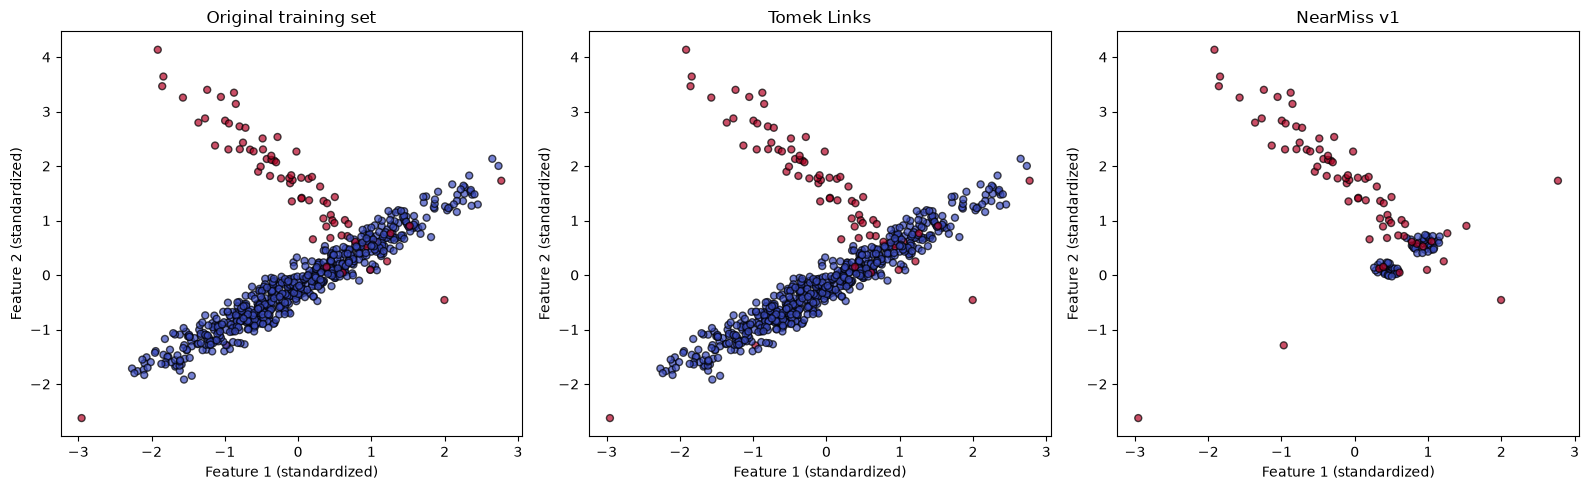

In [5]:
datasets = [
    ("Original training set", X_train_scaled, y_train),
    ("Tomek Links", X_tomek, y_tomek),
    ("NearMiss v1", X_nearmiss, y_nearmiss)
]

fig, axes = plt.subplots(1, 3, figsize=(16,5))
for ax, (title, X_data, y_data) in zip(axes, datasets):
    ax.scatter(
        X_data[:, 0], X_data[:, 1], c=y_data,
        cmap="coolwarm", alpha=0.7, edgecolors="k", s=25
    )
    ax.set_title(title)
    ax.set_xlabel("Feature 1 (standardized)")
    ax.set_ylabel("Feature 2 (standardized)")

plt.tight_layout()
plt.show()

### Q14. What visual differences do you observe between the three datasets?
#### Original dataset is having every data and tomek link looks almost similar like original, but some dots are deleted. While the Near Miss v1 has almost completely deleted blue data.

### Q15. Does NearMiss preserve the original distribution of the majority class? Discuss the possible consequences.
#### Nope, it literally deleted almost 80% of data, because of this it can be harsh for model to be accurate. Because of no data we can't predict anything.

---
# 7 Part 7 – Train and evaluate the classifiers

In [6]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

training_sets = {
    "Baseline": (X_train_scaled, y_train),
    "Tomek Links": (X_tomek, y_tomek),
    "NearMiss v1": (X_nearmiss, y_nearmiss)
}

results = []
confusion_matrices = {}

for name, (X_resampled, y_resampled) in training_sets.items():
    model = LogisticRegression(random_state=42)
    model.fit(X_resampled, y_resampled)
    y_pred = model.predict(X_test_scaled)
    
    results.append({
        "Method": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })
    
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

results_df = pd.DataFrame(results).set_index("Method")
print(results_df.round(3))

for name, matrix in confusion_matrices.items():
    print(f"\n{name} Confusion matrix")
    print(matrix)

             Accuracy  Balanced accuracy  Precision  Recall  F1-score
Method                                                               
Baseline         0.96              0.806      1.000   0.613     0.760
Tomek Links      0.96              0.806      1.000   0.613     0.760
NearMiss v1      0.97              0.869      0.958   0.742     0.836

Baseline Confusion matrix
[[269   0]
 [ 12  19]]

Tomek Links Confusion matrix
[[269   0]
 [ 12  19]]

NearMiss v1 Confusion matrix
[[268   1]
 [  8  23]]


### Q16. Which method achieves the highest recall for fraud detection?
### the nearmiss v1 have the highest recall for fraud detection.

### Q17. Which method achieves the highest F1-score?
#### Near miss v1

### Q18. Does the model with the highest accuracy also provide the best minority-class detection?
#### Yes, it detected the minority class very well.

### Q19. Compare false-positive and false-negative counts using the confusion matrices.
#### The base line and tomek link models missed 12 bad sectos in FP, but they didn't made any false negative prediction in FN. While nearmiss v1 missed only 8 in FP but 1 FN was the wrong prediction.

### Q20. If accuracy decreases but recall increases, could this be desirable for fraud detection? Justify your answer.
#### Yes, because it detected more bad sectors, so i think it's good condition to catch the frauds and detect them.

---
# 8 Part 8 – Compare the metrics visually

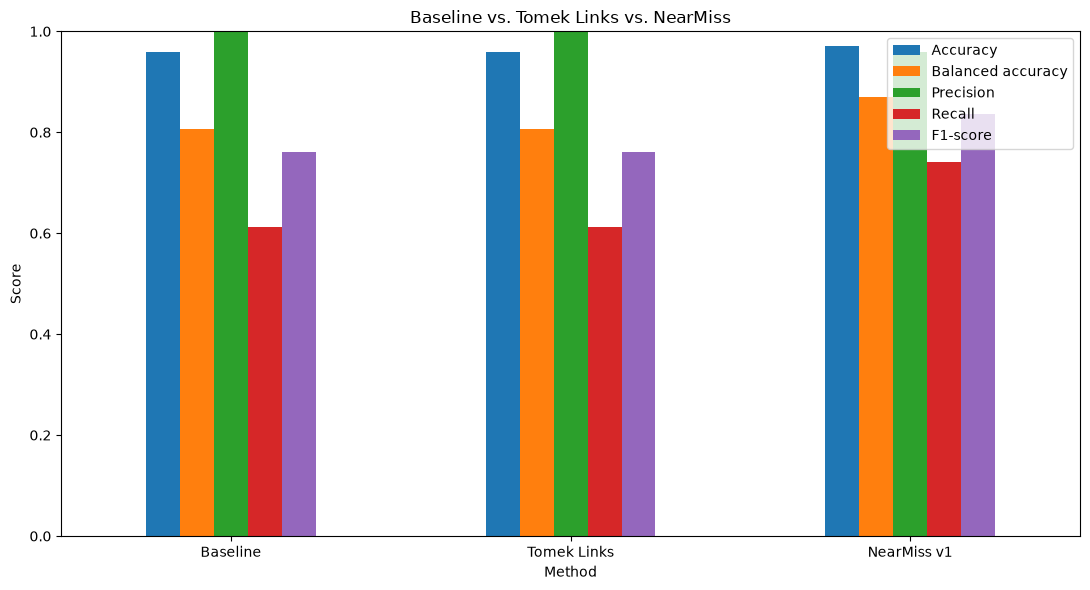

In [7]:
results_df[
    ["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(11, 6))
plt.title("Baseline vs. Tomek Links vs. NearMiss")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

---
# 9 Part 9 – Understand the Condensed Nearest Neighbor (CNN) Rule for Undersampling principle

***
# 10 Part 10 – Apply CNN undersampling

In [8]:
from imblearn.under_sampling import CondensedNearestNeighbour

cnn = CondensedNearestNeighbour(
    sampling_strategy="auto",
    random_state=42,
    n_neighbors=1
)

X_train_cnn, y_train_cnn = cnn.fit_resample(
    X_train, y_train
)

print("Original training size:", len(y_train))
print("Training size after CNN:", len(y_train_cnn))

print("\nClass distribution before CNN:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nClass distribution after CNN:")
print(pd.Series(y_train_cnn).value_counts().sort_index())

removed = len(y_train) - len(y_train_cnn)
reduction = 100 * removed / len(y_train)

print(f"\nRemoved observations: {removed}")
print(f"Training-set reduction: {reduction:.2f}%")

Original training size: 700
Training size after CNN: 131

Class distribution before CNN:
0    626
1     74
Name: count, dtype: int64

Class distribution after CNN:
0    57
1    74
Name: count, dtype: int64

Removed observations: 569
Training-set reduction: 81.29%


### Q21. How many observations remain after CNN undersampling?
#### there are only 131 samples left after it.

### Q22. How many majority-class observations have been removed?
#### it was 626 before it, but after running it was just 57

### Q23. What percentage of the original training set has been removed?
#### 81.29% of original dataset is been removed.

### Q24. Does CNN necessarily produce a balanced dataset? Explain your answer
#### No, it doesn't. because normal group at the end is 57 samples while other group is 74.

---
# 11 Part 11 – Visualize the effect of CNN

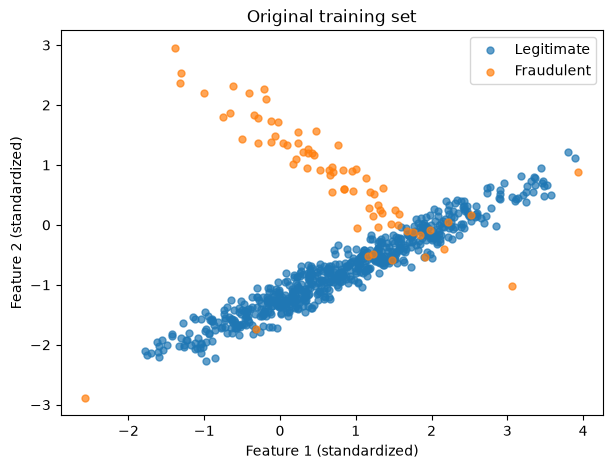

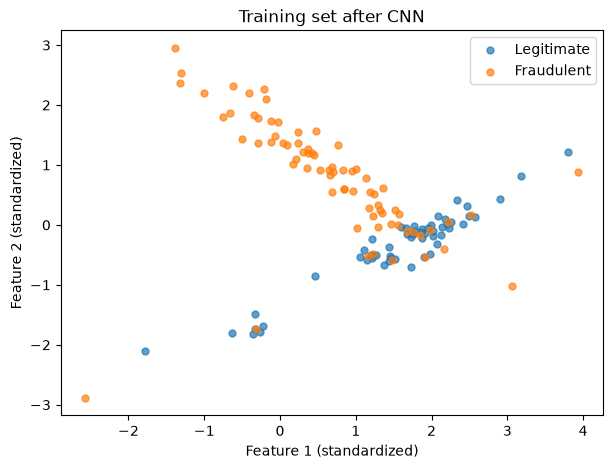

In [10]:
import numpy as np

def plot_dataset(X, y, title):
    plt.figure(figsize=(7,5))
    for label, name in [(0, "Legitimate"), (1, "Fraudulent")]:
        mask = np.asarray(y) == label
        plt.scatter(
            np.asarray(X)[mask, 0],
            np.asarray(X)[mask, 1],
            label=name,
            alpha=0.7,
            s=25
        )
    plt.title(title)
    plt.xlabel("Feature 1 (standardized)")
    plt.ylabel("Feature 2 (standardized)")
    plt.legend()
    plt.show()

plot_dataset(X_train, y_train, "Original training set")
plot_dataset(X_train_cnn, y_train_cnn, "Training set after CNN")

### Q25. Which regions of the feature space appear to have lost the most observations?
#### the blue part is majorly removed.

### Q26. Does the condensed dataset seem to preserve the boundary between the two classes? Support your answer with observations from the plots.
#### Yes, almost it has preserved. we can see the graph before the dots where colliding too much, but after running the next graph we see that are fewer and not overlapping.

---
# 12 Part 12 – Compare classification performance

### Q27. Evaluate both models on the same test set
#### we can clearly see that CNN did well. because it saved important edge samples. This is helping to detect more fraud samples.

### Q28. Compare CNN-Condensed with Tomek links and Near Miss.
#### CNN looks like a mix of both, making the balance and not removing necessary elements. Because tomek link set was almost similar, and near miss is like removing almost all data even important one. The CNN looks good combining both the capabilities.

---
# 13 Part 13 – Further investigation

#### Test 1: Repeat the experiment with n_neighbors=3. How does the retained subset change?

In [17]:
# change the number inside the tool
cnn_three = CondensedNearestNeighbour(
    sampling_strategy="auto",
    random_state=42,
    n_neighbors=3
)

X_train_cnn3, y_train_cnn3 = cnn_three.fit_resample(X_train, y_train)

print("Dots left after using 3 neighbors:", len(y_train_cnn3))

Dots left after using 3 neighbors: 114


#### Test 2: Change the class distribution from 90

In [18]:
# fake dataset with a harder split
X_hard, y_hard = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05], # 95% normal and 5% bad
    class_sep=0.8,
    random_state=42
)

print("New extreme pile:", Counter(y_hard))

New extreme pile: Counter({np.int64(0): 945, np.int64(1): 55})


#### Test 3: Compare CNN with random undersampling. Which method removes more observations, and which gives better minority-class recall?

In [19]:
from imblearn.under_sampling import RandomUnderSampler

random_cutter = RandomUnderSampler(random_state=42)
X_random, y_random = random_cutter.fit_resample(X_train_scaled, y_train)

print("Dots left after totally random cuts:", len(y_random))

Dots left after totally random cuts: 148


#### Test 4: Repeat the experiment with at least five different random seeds. Are the results stable?

In [20]:
# We use a loop to test the blind cutter five separate times
seed_list = [10, 25, 42, 77, 99]

for seed_number in seed_list:
    cutter = RandomUnderSampler(random_state=seed_number)
    X_seed, y_seed = cutter.fit_resample(X_train_scaled, y_train)
    
    # We can train a quick model to see how the score wiggles
    model = LogisticRegression(random_state=42)
    model.fit(X_seed, y_seed)
    score = model.score(X_test_scaled, y_test)
    
    print(f"Seed {seed_number} score: {score:.3f}")

Seed 10 score: 0.950
Seed 25 score: 0.947
Seed 42 score: 0.910
Seed 77 score: 0.873
Seed 99 score: 0.957


### Propose an evaluation protocol for selecting an undersampling strategy in a real fraud-detection application. Consider the costs of false negatives, false positives, computational efficiency, and variation across train/test splits.

#### 3 neighbors: When we use 3 neighbors, the dataset becomes even smaller only 114 dots. Because it checks multiple points instead of 1 point now. So it will drop the more.

#### change to 95|5 : there is too much gap and that's why it became much smaller to make a more balancing one while undersampling.

#### Random vs CNN : it's like randomly removing the samples while CNN checks for points.

#### Five Random Seeds: we can see the seed 99 have highest score 0.957 but i think it needs the middle score like 42 to be better.

#### Real Evaluation Protocol: I think it needs to be balancing to select the actual fraud case in real life. But instead of one test only we need to test data multiple times so we can confirm to move forward and choose the actual model we need for it to predict the fraud and leave the legitimate transaction.

---
# Discussion and conclusion

### Q25. Summarize the main difference between Tomek Links and NearMiss v1.
#### Tomek link to only some overlapping points while Nearmiss v1 is like extremely removing the complete dataset around 80% of reduction.

### Q26. Why must resampling be performed only on the training set?
#### Because if we change the test data, prediction can make false predictions more.

### Q27. What are the advantages and limitations of each method?
#### Tomek Link is safe and doesn't remove the most of part but it's not balancing the data. Nearmiss v1 is forcing equal balance so we can find tiny frauds too, but it completely destroys the natural data spread shape. CNN tool is combination of both, but it's still not perfect equal.

### Q28. Which method would you recommend for this fraud-detection task? Support your recommendation with the evaluation results.
#### I prefer Near miss v1 method because it have fewer false predictions. we can clearly see from above methods.

### Q29. Suggest a more robust experimental protocol using stratified cross-validation.
#### Instead of only 1 dataset , i think we should split data into several parts and then we should try to evaluate them.